# 05 · DAG and Bayesian network
**Owner:** Jagruthi Pulumati

1. Turn the predicted "X directly causes Y" claims into one DAG per test premise (no self-loops, no cycles)
2. Measure **edge precision** against the true edges
3. Fit a **pgmpy Bayesian network** and answer intervention questions like P(Y | do(X))

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")  # hide pgmpy deprecation messages

from pgmpy.estimators import BayesianEstimator
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import CausalInference, VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.sampling import BayesianModelSampling

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"

from src.parser import parse_hypothesis

SEED = 42
predictions = pd.read_csv(PROCESSED / "test_predictions.csv")
graphs = pd.read_csv(PROCESSED / "premise_graphs.csv").query("split == 'test'").fillna("").set_index("premise_id")

## 1. Candidate edges
Every "X directly causes Y" claim the model predicted as valid becomes an edge X → Y, with its confidence and the
sentence it came from.

In [2]:
parsed = predictions["hypothesis"].map(parse_hypothesis)
predictions["relation"] = [h.relation for h in parsed]
predictions["x"] = [h.x for h in parsed]
predictions["y"] = [h.y for h in parsed]

direct = predictions[predictions["relation"] == "direct_cause"]
candidates = direct[direct["pred"] == 1]
print(len(direct), "direct-cause claims,", len(candidates), "predicted valid")

388 direct-cause claims, 73 predicted valid


## 2. Build the DAGs
Edges are added most confident first. An edge is rejected if it is a self-loop, uses a variable outside the premise,
is a duplicate, or would create a cycle.

In [3]:
def build_dag(variables, edges):
    dag = nx.DiGraph()
    dag.add_nodes_from(variables)
    log = []
    for e in sorted(edges, key=lambda e: -e["confidence"]):
        x, y = e["x"], e["y"]
        if x == y:
            status = "rejected: self-loop"
        elif x not in variables or y not in variables:
            status = "rejected: unknown variable"
        elif dag.has_edge(x, y):
            status = "rejected: duplicate"
        elif nx.has_path(dag, y, x):
            status = "rejected: cycle"
        else:
            dag.add_edge(x, y, source=e["source"])
            status = "kept"
        log.append({**e, "status": status})
    return dag, log


dags, log = {}, []
for pid, row in graphs.iterrows():
    edges = [{"x": r.x, "y": r.y, "confidence": r.proba, "source": r.hypothesis}
             for r in candidates[candidates["premise_id"] == pid].itertuples()]
    dags[pid], premise_log = build_dag(row["variables"].split(","), edges)
    log += premise_log

print(pd.DataFrame(log)["status"].value_counts())
assert all(nx.is_directed_acyclic_graph(g) for g in dags.values())

status
kept    73
Name: count, dtype: int64


No edge had to be rejected on the real predictions. A quick check with bad edges shows the rules work:

In [4]:
bad = [{"x": "A", "y": "B", "confidence": 0.9, "source": "demo"},
       {"x": "B", "y": "C", "confidence": 0.8, "source": "demo"},
       {"x": "C", "y": "A", "confidence": 0.6, "source": "demo"},   # makes a cycle
       {"x": "B", "y": "B", "confidence": 0.7, "source": "demo"},   # self-loop
       {"x": "A", "y": "G", "confidence": 0.5, "source": "demo"}]   # G not in the premise
pd.DataFrame(build_dag(["A", "B", "C"], bad)[1])

,x,y,confidence,source,status
0,A,B,0.9,demo,kept
1,B,C,0.8,demo,kept
2,B,B,0.7,demo,rejected: self-loop
3,C,A,0.6,demo,rejected: cycle
4,A,G,0.5,demo,rejected: unknown variable


## 3. Edge precision
The true edges are the "directly causes" claims with label 1. Edge precision = correct edges ÷ edges we drew.

In [5]:
true_edges = {pid: {(r.x, r.y) for r in direct[(direct["premise_id"] == pid) & (direct["label"] == 1)].itertuples()}
              for pid in graphs.index}
pc_edges = {pid: {tuple(e.split("->")) for e in graphs.loc[pid, "directed_edges"].split(";") if e}
            for pid in graphs.index}


def edge_scores(truth):
    predicted = {(pid, *e) for pid, g in dags.items() for e in g.edges}
    true = {(pid, *e) for pid, edges in truth.items() for e in edges}
    correct = len(predicted & true)
    return {"edges drawn": len(predicted), "true edges": len(true), "correct": correct,
            "edge precision": correct / len(predicted), "edge recall": correct / len(true)}


pd.DataFrame({"vs dataset labels": edge_scores(true_edges), "vs PC edges": edge_scores(pc_edges)}).T.round(3)

,edges drawn,true edges,correct,edge precision,edge recall
vs dataset labels,73.0,65.0,65.0,0.89,1.000
vs PC edges,73.0,77.0,73.0,1.00,0.948


Every true edge is found (recall 1.0). The extra edges are ones PC supports but the dataset labels as 0, so precision
against the PC graph is 1.0.

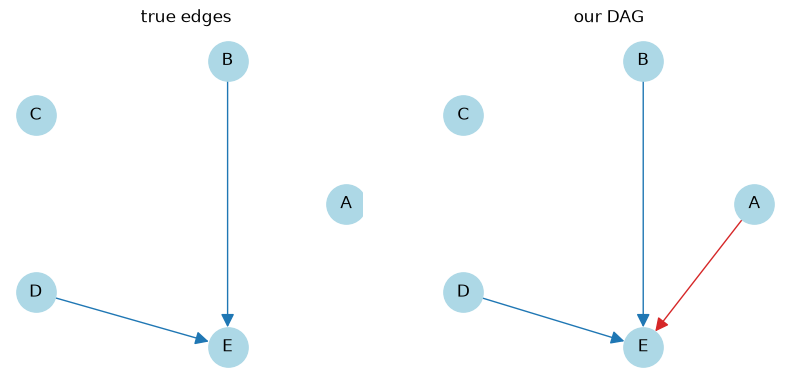

In [6]:
# one predicted DAG next to the truth
pid = next(p for p in dags if dags[p].number_of_edges() >= 3 and set(dags[p].edges) != true_edges[p])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (title, edges) in zip(axes, [("true edges", true_edges[pid]), ("our DAG", set(dags[pid].edges))]):
    g = nx.DiGraph(list(edges))
    g.add_nodes_from(dags[pid].nodes)
    colors = ["tab:blue" if e in true_edges[pid] else "tab:red" for e in g.edges]
    nx.draw_networkx(g, nx.circular_layout(sorted(g.nodes)), ax=ax, node_color="lightblue",
                     node_size=800, edge_color=colors, arrowsize=20)
    ax.set_title(title)
    ax.axis("off")
plt.show()

Red = an edge we drew that is not in the true graph.